# IPL Player Performance Prediction

This notebook walks through data loading, exploratory data analysis (EDA), feature engineering, model training, comparison, and evaluation for predicting an IPL batsman's runs scored in a match.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

sns.set_theme(style='whitegrid')

## 1. Load Dataset

In [2]:
df = pd.read_csv('../data/ipl_player_performance.csv')
df.head()

,player_name,team,opponent,venue,season,batting_position,matches_played_season,avg_runs_last5,avg_strike_rate_last5,avg_balls_faced_last5,home_advantage,toss_won,pitch_type,opponent_bowling_rank,runs_scored
0,N Pooran,LSG,CSK,Ekana Stadium,2024,4,12,50.15,169.84,27.63,0,0,Batting,9,69
1,RA Jadeja,MI,LSG,Sawai Mansingh Stadium,2019,1,12,41.83,155.63,16.61,0,1,Bowling,1,42
2,AT Rayudu,RR,SRH,Rajiv Gandhi Intl Stadium,2023,3,12,33.29,87.42,28.27,0,0,Bowling,7,25
3,Q de Kock,LSG,RCB,Sawai Mansingh Stadium,2019,4,8,37.74,169.59,39.78,1,1,Bowling,3,38
4,G Maxwell,CSK,LSG,Arun Jaitley Stadium,2024,4,8,26.34,149.96,17.98,1,1,Batting,9,33


In [3]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   player_name            2500 non-null   object 
 1   team                   2500 non-null   object 
 2   opponent               2500 non-null   object 
 3   venue                  2500 non-null   object 
 4   season                 2500 non-null   int64  
 5   batting_position       2500 non-null   int64  
 6   matches_played_season  2500 non-null   int64  
 7   avg_runs_last5         2500 non-null   float64
 8   avg_strike_rate_last5  2500 non-null   float64
 9   avg_balls_faced_last5  2500 non-null   float64
 10  home_advantage         2500 non-null   int64  
 11  toss_won               2500 non-null   int64  
 12  pitch_type             2500 non-null   object 
 13  opponent_bowling_rank  2500 non-null   int64  
 14  runs_scored            2500 non-null   int64  
dtypes: f

,season,batting_position,matches_played_season,avg_runs_last5,avg_strike_rate_last5,avg_balls_faced_last5,home_advantage,toss_won,opponent_bowling_rank,runs_scored
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2500.00000,2500.000000,2500.000000
mean,2021.526800,4.036000,9.970400,35.816644,137.015888,25.120432,0.491600,0.47880,5.538400,43.632800
std,1.697538,2.007266,3.193494,17.513100,24.246854,9.737450,0.500029,0.49965,2.836996,18.649619
min,2019.000000,1.000000,5.000000,0.000000,60.000000,5.000000,0.000000,0.00000,1.000000,0.000000
25%,2020.000000,2.000000,7.000000,23.585000,120.470000,18.327500,0.000000,0.00000,3.000000,30.000000
50%,2022.000000,4.000000,10.000000,35.460000,137.250000,24.835000,0.000000,0.00000,6.000000,43.500000
75%,2023.000000,6.000000,13.000000,47.410000,154.130000,31.905000,1.000000,1.00000,8.000000,56.000000
max,2024.000000,7.000000,15.000000,100.260000,213.620000,58.780000,1.000000,1.00000,10.000000,116.000000


## 2. Exploratory Data Analysis (EDA)

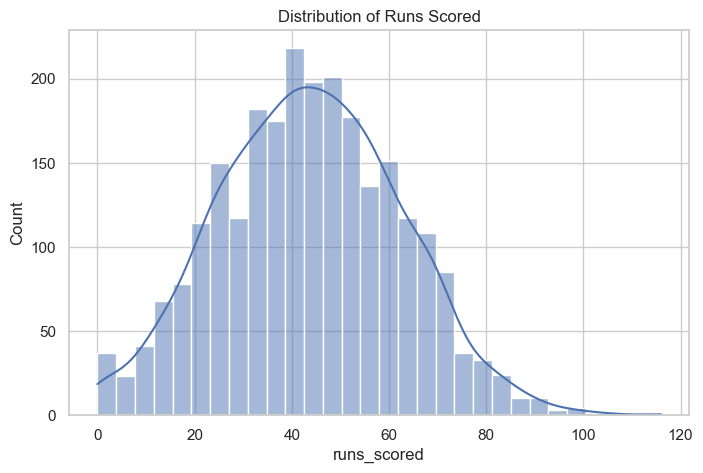

In [4]:
plt.figure(figsize=(8,5))
sns.histplot(df['runs_scored'], bins=30, kde=True)
plt.title('Distribution of Runs Scored')
plt.show()

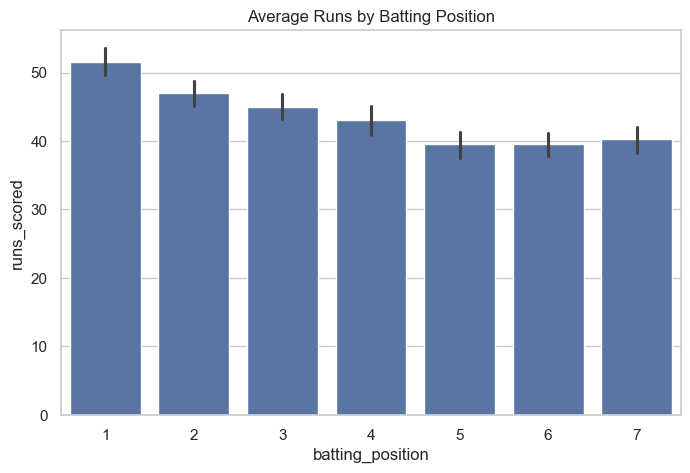

In [5]:
plt.figure(figsize=(8,5))
sns.barplot(data=df, x='batting_position', y='runs_scored')
plt.title('Average Runs by Batting Position')
plt.show()

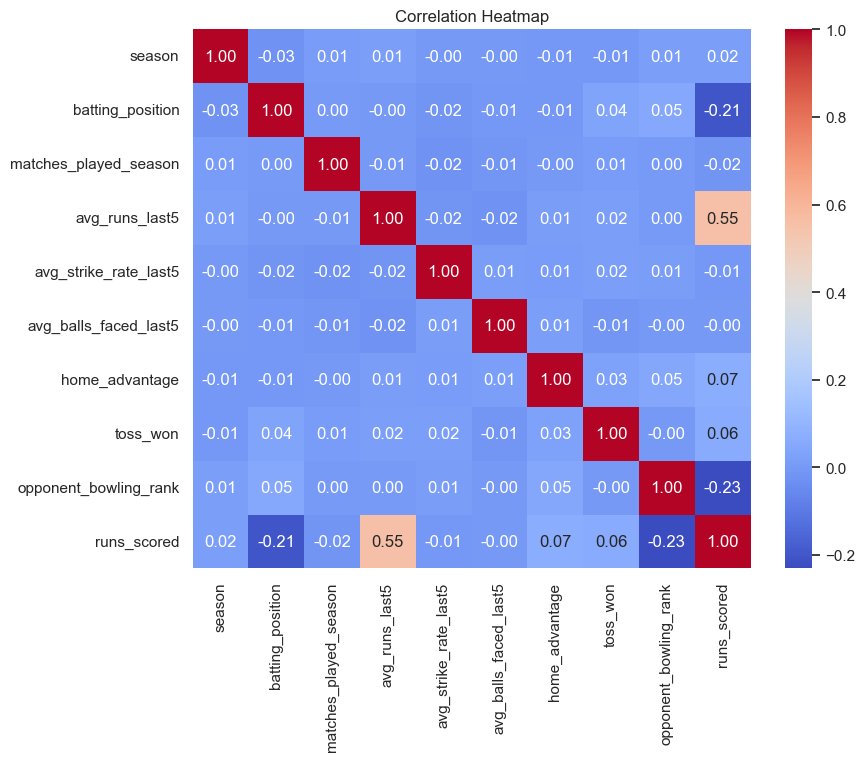

In [6]:
plt.figure(figsize=(9,7))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

## 3. Feature Engineering & Train-Test Split

In [7]:
target = 'runs_scored'
X = df.drop(columns=[target])
y = df[target]

categorical_cols = ['player_name', 'team', 'opponent', 'venue', 'pitch_type']
numeric_cols = [c for c in X.columns if c not in categorical_cols]

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(2000, 14) (500, 14)


## 4. Model Training & Comparison

In [8]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Decision Tree': DecisionTreeRegressor(max_depth=8, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, max_depth=4, random_state=42),
    'XGBoost': XGBRegressor(n_estimators=200, max_depth=4, learning_rate=0.08, random_state=42)
}

results = {}
pipelines = {}

for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)

    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)

    results[name] = {'MAE': round(mae,3), 'RMSE': round(rmse,3), 'R2': round(r2,4)}
    pipelines[name] = pipe

results_df = pd.DataFrame(results).T.sort_values('R2', ascending=False)
results_df

,MAE,RMSE,R2
Linear Regression,10.039,12.647,0.5539
Ridge Regression,10.040,12.649,0.5538
XGBoost,10.325,13.191,0.5147
Gradient Boosting,10.516,13.242,0.5110
Random Forest,11.108,14.068,0.4480
Decision Tree,12.755,16.152,0.2724


## 5. Model Comparison Visualization

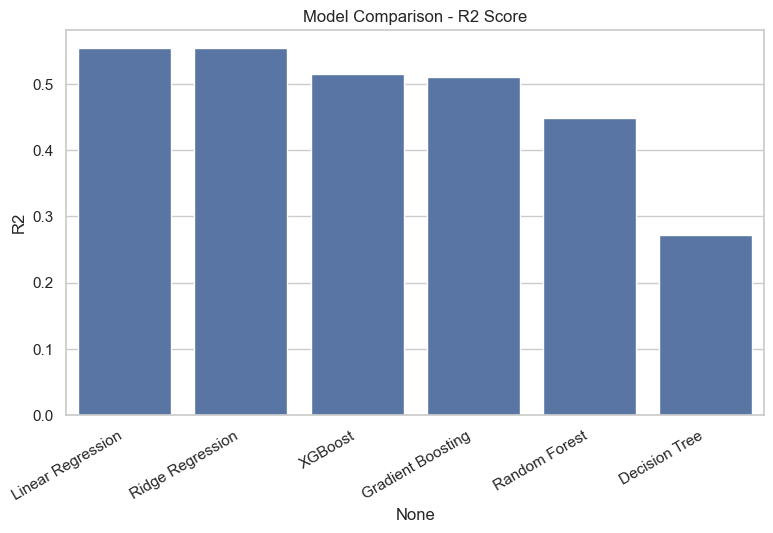

In [9]:
plt.figure(figsize=(9,5))
sns.barplot(x=results_df.index, y=results_df['R2'])
plt.title('Model Comparison - R2 Score')
plt.xticks(rotation=30, ha='right')
plt.show()

## 6. Best Model - Actual vs Predicted

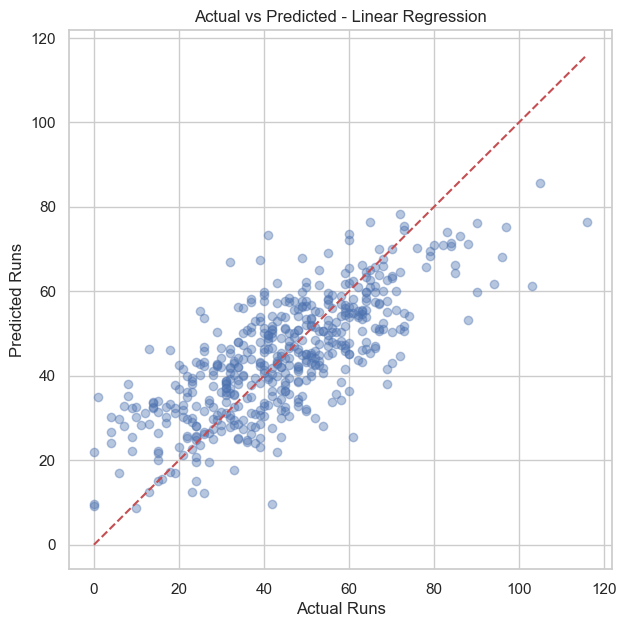

Best Model: Linear Regression
MAE     10.0390
RMSE    12.6470
R2       0.5539
Name: Linear Regression, dtype: float64


In [10]:
best_name = results_df.index[0]
best_pipe = pipelines[best_name]
preds = best_pipe.predict(X_test)

plt.figure(figsize=(7,7))
plt.scatter(y_test, preds, alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Runs')
plt.ylabel('Predicted Runs')
plt.title(f'Actual vs Predicted - {best_name}')
plt.show()

print(f'Best Model: {best_name}')
print(results_df.loc[best_name])

## 7. Conclusion

The best performing model based on R2 score was selected and saved as `models/best_model.pkl`. See the README for full metrics, model comparison, and future improvement ideas.